# Importaciones minerales de Argentina

**Objetivo:** describir la evolución del valor CIF, su composición mineral y los países de origen; descomponer el aumento de 2021 y explorar la relación entre origen y procedencia en el caso del uranio.

**Archivo de entrada:** `impominerales-siacam(3).csv`, en la misma carpeta que este notebook. Fuente identificada por el nombre del archivo: SIACAM; completar enlace de descarga y fecha de consulta antes de publicar.

**Alcance:** histórico 1994–2025. Las salidas guardadas muestran registros hasta junio de 2026; ese año parcial queda fuera de las comparaciones anuales. La marca `PERIODO_COMPLETO` usa el corte elegido (2025), no verifica por sí sola la cobertura de doce meses.

**Lectura:** los importes son valores CIF nominales en USD. Sus cambios no permiten distinguir precios de cantidades ni demostrar sus causas económicas. Los rankings históricos suman todo el período y no representan necesariamente la estructura actual.

## 1. Carga y diagnóstico

Inspeccionamos la estructura de la base, los tipos de datos, los valores faltantes y los duplicados. Este diagnóstico permite identificar limitaciones antes de calcular indicadores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Formato visual: punto para miles y coma para decimales.
# No modifica los valores ni la precisión de los cálculos.
def formato_numero(valor):
    return f"{valor:,.2f}".translate(str.maketrans({",": ".", ".": ","}))

pd.options.display.float_format = formato_numero
np.set_printoptions(suppress=True)
plt.rcParams["axes.formatter.limits"] = (-100, 100)
plt.rcParams["axes.formatter.useoffset"] = False


# Cargar dataset
df = pd.read_csv("impominerales-siacam(3).csv")

print("Dimensiones:", df.shape)

display(df.head())

print("\nTipos de datos:")
print(df.dtypes)

print("\nValores faltantes:")
print(df.isna().sum())

print("\nDuplicados:", df.duplicated().sum())

print("\nAños:", df["ANYO"].min(), "-", df["ANYO"].max())

print("\nCantidad de grupos minerales:", df["GRUPO"].nunique())
print("Cantidad de países:", df["ORIGEN"].nunique())
print("Cantidad de sectores:", df["SECTOR"].nunique())

Dimensiones: (101437, 8)

Tipos de datos:
ANYO           int64
ORIGEN        object
PPRO         float64
PROCEDENC     object
MES            int64
GRUPO         object
SECTOR        object
CIF          float64
dtype: object

Valores faltantes:
ANYO         0
ORIGEN       4
PPRO         4
PROCEDENC    4
MES          0
GRUPO        0
SECTOR       0
CIF          0
dtype: int64

Duplicados: 0

Años: 1994 - 2026

Cantidad de grupos minerales: 101
Cantidad de países: 152
Cantidad de sectores: 5


,ANYO,ORIGEN,PPRO,PROCEDENC,MES,GRUPO,SECTOR,CIF
0,1994,Alemania,"406,00",Belgica,1,Demas minerales n.c.p,No metaliferos,"20.944,00"
1,1994,Alemania,"423,00",Paises Bajos,1,Magnesio,No metaliferos,"8.925,00"
2,1994,Alemania,"430,00",Suiza,1,Aluminio,Metaliferos,"1.010,00"
3,1994,Alemania,"438,00",Alemania,1,Aluminio,Metaliferos,"13.155,00"
4,1994,Alemania,"438,00",Alemania,1,Arenas,No metaliferos,"604,00"


## 2. Preparación y corte temporal

Construimos una fecha mensual y delimitamos las comparaciones anuales a 1994–2025. La presencia de registros en los doce meses se comprueba para la base general; no garantiza que cada mineral tenga registros todos los meses ni que la fuente sea exhaustiva.

In [2]:
# Creamos una copia para trabajar sin modificar el dataset original
data = df.copy()

# Construimos una fecha mensual
data["FECHA"] = pd.to_datetime(
    dict(
        year=data["ANYO"],
        month=data["MES"],
        day=1
    )
)

# Identificamos los registros sin país de origen
data["ORIGEN"] = data["ORIGEN"].fillna("Sin dato")

# Marcamos cuáles pertenecen a años completos
data["PERIODO_COMPLETO"] = data["ANYO"] <= 2025

# Revisamos el resultado
display(data.head())

print("Fecha mínima:", data["FECHA"].min())
print("Fecha máxima:", data["FECHA"].max())

print("\nRegistros por período:")
print(data["PERIODO_COMPLETO"].value_counts())

# Verificamos meses presentes en el conjunto de la base.
cobertura_mensual = data.groupby("ANYO")["MES"].nunique()
anios_incompletos = cobertura_mensual.loc[lambda s: (s.index <= 2025) & (s < 12)]
print("Años hasta 2025 con menos de 12 meses en la base:", anios_incompletos.to_dict())


Fecha mínima: 1994-01-01 00:00:00
Fecha máxima: 2026-06-01 00:00:00

Registros por período:
PERIODO_COMPLETO
True     99883
False     1554
Name: count, dtype: int64
Años hasta 2025 con menos de 12 meses en la base: {}


,ANYO,ORIGEN,PPRO,PROCEDENC,MES,GRUPO,SECTOR,CIF,FECHA,PERIODO_COMPLETO
0,1994,Alemania,"406,00",Belgica,1,Demas minerales n.c.p,No metaliferos,"20.944,00",1994-01-01,True
1,1994,Alemania,"423,00",Paises Bajos,1,Magnesio,No metaliferos,"8.925,00",1994-01-01,True
2,1994,Alemania,"430,00",Suiza,1,Aluminio,Metaliferos,"1.010,00",1994-01-01,True
3,1994,Alemania,"438,00",Alemania,1,Aluminio,Metaliferos,"13.155,00",1994-01-01,True
4,1994,Alemania,"438,00",Alemania,1,Arenas,No metaliferos,"604,00",1994-01-01,True


## 3. Composición histórica: minerales y países

¿Qué minerales y países de origen concentran el valor importado? Los rankings suman el CIF de 1994–2025 y describen la composición histórica; no representan necesariamente la estructura del último año.

In [3]:
# Nos quedamos con años completos para el análisis histórico
historico = data[data["PERIODO_COMPLETO"]].copy()

# Sumamos el valor CIF por grupo mineral
ranking_minerales = (
    historico
    .groupby("GRUPO", as_index=False)["CIF"]
    .sum()
    .sort_values("CIF", ascending=False)
)

# Calculamos participación sobre el total
ranking_minerales["PARTICIPACION"] = (
    ranking_minerales["CIF"] / ranking_minerales["CIF"].sum() * 100
)

# Calculamos participación acumulada
ranking_minerales["PARTICIPACION_ACUMULADA"] = (
    ranking_minerales["PARTICIPACION"].cumsum()
)

display(ranking_minerales.head(15))


,GRUPO,CIF,PARTICIPACION,PARTICIPACION_ACUMULADA
55,Hierro,"15.083.245.160,96","40,00","40,00"
2,Aluminio,"6.729.701.828,74","17,85","57,85"
48,Ferroaleaciones,"3.045.723.819,90","8,08","65,93"
35,Cobre,"1.669.423.602,23","4,43","70,36"
30,Cinc,"1.634.876.672,87","4,34","74,70"
81,Potasio,"898.504.192,35","2,38","77,08"
16,Bauxita,"669.008.593,11","1,77","78,85"
50,Fosfatos,"648.898.409,62","1,72","80,57"
14,Azufre,"583.066.765,73","1,55","82,12"
83,Sulfatos,"529.958.354,09","1,41","83,53"


In [4]:
# Sumamos el valor CIF por país de origen
ranking_paises = (
    historico
    .groupby("ORIGEN", as_index=False)["CIF"]
    .sum()
    .sort_values("CIF", ascending=False)
)

# Participación porcentual
ranking_paises["PARTICIPACION"] = (
    ranking_paises["CIF"] / ranking_paises["CIF"].sum() * 100
)

# Participación acumulada
ranking_paises["PARTICIPACION_ACUMULADA"] = (
    ranking_paises["PARTICIPACION"].cumsum()
)

display(ranking_paises.head(15))

,ORIGEN,CIF,PARTICIPACION,PARTICIPACION_ACUMULADA
19,Brasil,"22.182.939.362,32","58,84","58,84"
10,Australia,"2.739.017.035,92","7,26","66,10"
23,Chile,"2.655.536.194,05","7,04","73,14"
24,China,"1.452.814.649,33","3,85","77,00"
22,Canada,"1.130.093.355,15","3,00","79,99"
41,Estados Unidos,"1.000.173.066,20","2,65","82,65"
108,Peru,"789.538.247,80","2,09","84,74"
128,Sudafrica,"515.130.287,07","1,37","86,11"
40,España,"491.665.171,08","1,30","87,41"
120,Rusia,"394.565.733,33","1,05","88,46"


**Lectura:** hierro y aluminio suman alrededor del 57,9 % del CIF histórico; Brasil concentra el 58,8 % por país de origen. Son dos perspectivas de concentración sobre el mismo conjunto de importaciones.

In [5]:
# Los ocho minerales se seleccionan por su CIF acumulado en 1994–2025.
top_minerales = ranking_minerales.head(8)["GRUPO"].tolist()
print("Minerales seleccionados:", top_minerales)

Minerales seleccionados: ['Hierro', 'Aluminio', 'Ferroaleaciones', 'Cobre', 'Cinc', 'Potasio', 'Bauxita', 'Fosfatos']


## 4. Evolución anual

¿Cómo cambia el valor importado a lo largo del tiempo? Comparamos el CIF anual y su variación interanual para distinguir niveles altos de aumentos rápidos. Los valores son nominales: no separan cambios de precios y cantidades.

In [6]:
# Sumamos el valor CIF total de cada año completo
cif_anual = (
    historico
    .groupby("ANYO", as_index=False)["CIF"]
    .sum()
)

# Convertimos el CIF a millones de USD para facilitar la lectura
cif_anual["CIF_MILLONES"] = cif_anual["CIF"] / 1_000_000

display(cif_anual)

,ANYO,CIF,CIF_MILLONES
0,1994,"353.802.176,00","353,80"
1,1995,"520.998.398,00","521,00"
2,1996,"559.035.569,00","559,04"
3,1997,"605.447.547,00","605,45"
4,1998,"588.823.045,67","588,82"
5,1999,"462.198.617,15","462,20"
6,2000,"558.635.618,71","558,64"
7,2001,"479.154.100,82","479,15"
8,2002,"397.790.260,14","397,79"
9,2003,"489.675.333,94","489,68"


In [7]:
# Calculamos la variación porcentual respecto al año anterior
cif_anual["VARIACION_PCT"] = (
    cif_anual["CIF_MILLONES"].pct_change() * 100
)

# Año con mayor CIF
maximo = cif_anual.loc[cif_anual["CIF_MILLONES"].idxmax()]

# Año con menor CIF
minimo = cif_anual.loc[cif_anual["CIF_MILLONES"].idxmin()]

print(
    f"Máximo: {int(maximo['ANYO'])} - "
    f"USD {maximo['CIF_MILLONES']:.1f} millones"
)

print(
    f"Mínimo: {int(minimo['ANYO'])} - "
    f"USD {minimo['CIF_MILLONES']:.1f} millones"
)

print("\nMayores aumentos interanuales:")
display(
    cif_anual.nlargest(5, "VARIACION_PCT")[
        ["ANYO", "CIF_MILLONES", "VARIACION_PCT"]
    ]
)

print("\nMayores caídas interanuales:")
display(
    cif_anual.nsmallest(5, "VARIACION_PCT")[
        ["ANYO", "CIF_MILLONES", "VARIACION_PCT"]
    ]
)

Máximo: 2011 - USD 2297.5 millones
Mínimo: 1994 - USD 353.8 millones

Mayores aumentos interanuales:

Mayores caídas interanuales:


,ANYO,CIF_MILLONES,VARIACION_PCT
27,2021,"1.950,78","116,53"
16,2010,"1.680,46","93,07"
14,2008,"2.137,53","62,04"
1,1995,"521,00","47,26"
10,2004,"707,97","44,58"


,ANYO,CIF_MILLONES,VARIACION_PCT
15,2009,"870,40","-59,28"
25,2019,"1.209,78","-29,55"
22,2016,"980,52","-28,36"
18,2012,"1.678,45","-26,94"
26,2020,"900,95","-25,53"


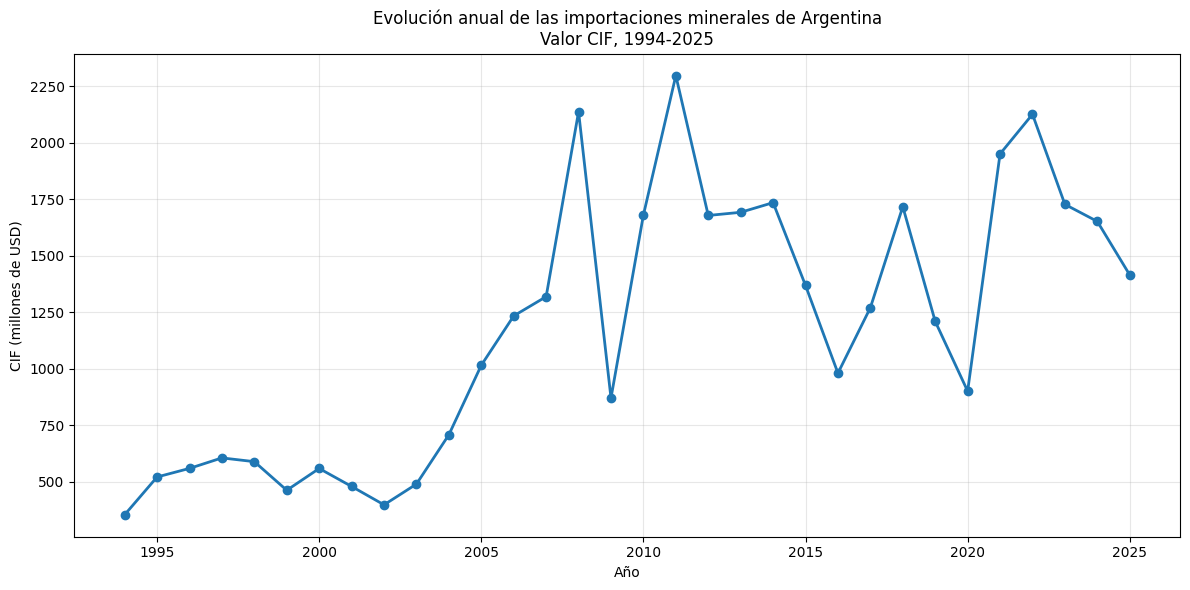

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(
    cif_anual["ANYO"],
    cif_anual["CIF_MILLONES"],
    marker="o",
    linewidth=2
)

plt.title(
    "Evolución anual de las importaciones minerales de Argentina\n"
    "Valor CIF, 1994-2025"
)

plt.xlabel("Año")
plt.ylabel("CIF (millones de USD)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Variación interanual
El nivel total y su tasa de cambio responden preguntas diferentes. El porcentaje se calcula respecto del año anterior, sin incluir 2026.

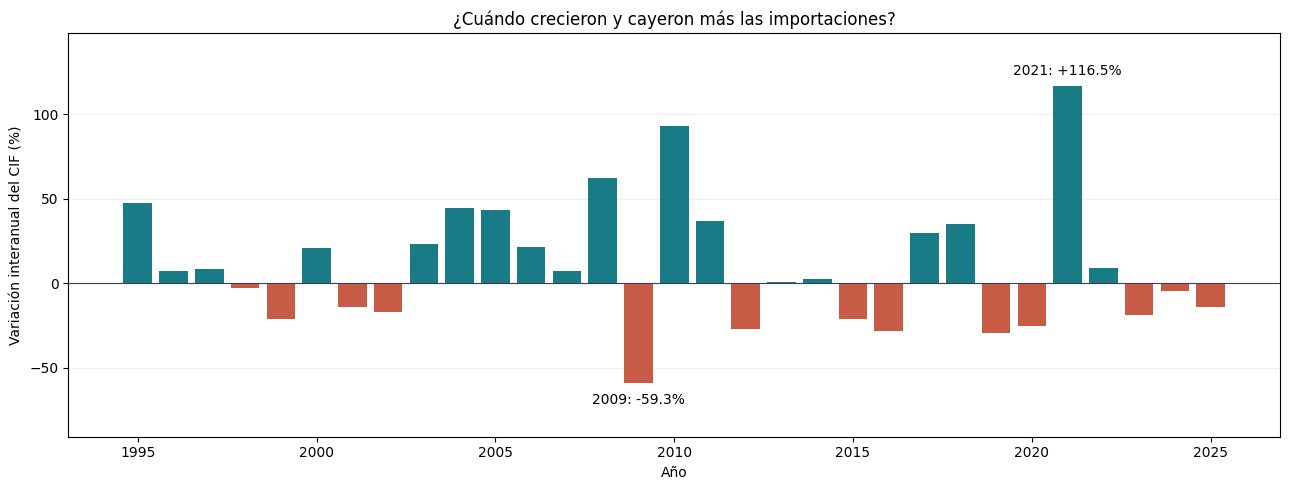

In [9]:
# La primera observación no tiene un año anterior con el que compararse.
variaciones = cif_anual.dropna(subset=["VARIACION_PCT"])
fig, ax = plt.subplots(figsize=(13, 5))
colores = ["#197b86" if valor >= 0 else "#c65b46"
           for valor in variaciones["VARIACION_PCT"]]
ax.bar(variaciones["ANYO"], variaciones["VARIACION_PCT"], color=colores)
ax.axhline(0, color="#374151", linewidth=0.8)
for indice in [variaciones["VARIACION_PCT"].idxmax(),
               variaciones["VARIACION_PCT"].idxmin()]:
    fila = variaciones.loc[indice]
    valor = fila["VARIACION_PCT"]
    ax.annotate(f"{int(fila['ANYO'])}: {valor:+.1f}%",
                (fila["ANYO"], valor), xytext=(0, 8 if valor >= 0 else -15),
                textcoords="offset points", ha="center", fontsize=10)
ax.set(title="¿Cuándo crecieron y cayeron más las importaciones?",
       xlabel="Año", ylabel="Variación interanual del CIF (%)")
ax.margins(y=0.18)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

**Lectura:** el máximo nominal se alcanza en 2011, mientras que el mayor aumento porcentual corresponde a 2021. El año de mayor valor importado y el de crecimiento más rápido responden preguntas diferentes.

## 5. Descomposición del salto de 2021

¿Qué minerales aportaron al aumento de 2021 frente a 2020? Descomponemos la diferencia en dólares y luego examinamos los países de origen del hierro, el principal contribuyente. Los aportes explican la suma contable, sin establecer causas económicas.

In [10]:
# CIF por mineral en 2020 y 2021
cambio_2021 = (
    data[data["ANYO"].isin([2020, 2021])]
    .groupby(["GRUPO", "ANYO"])["CIF"]
    .sum()
    .unstack(fill_value=0)
)

# Cambio absoluto entre ambos años
cambio_2021["CAMBIO_USD"] = (
    cambio_2021[2021] - cambio_2021[2020]
)

# Pasamos a millones
cambio_2021["CAMBIO_MILLONES"] = (
    cambio_2021["CAMBIO_USD"] / 1_000_000
)

# Ordenamos por los minerales que más explican el aumento
cambio_2021 = cambio_2021.sort_values(
    "CAMBIO_MILLONES",
    ascending=False
)

display(cambio_2021.head(10))

ANYO,2020,2021,CAMBIO_USD,CAMBIO_MILLONES
GRUPO,,,,
Hierro,"339.366.474,51","1.050.823.909,49","711.457.434,98","711,46"
Ferroaleaciones,"53.316.078,17","158.128.959,76","104.812.881,59","104,81"
Aluminio,"178.244.947,51","241.935.369,21","63.690.421,70","63,69"
Cinc,"69.138.418,00","109.716.227,80","40.577.809,80","40,58"
Fosfatos,"19.793.901,38","37.438.148,70","17.644.247,32","17,64"
Potasio,"35.883.795,33","51.248.397,95","15.364.602,62","15,36"
Baritina,"6.160.319,02","18.776.033,11","12.615.714,09","12,62"
Uranio,"11.606.645,29","23.588.267,33","11.981.622,04","11,98"
Azufre,"11.886.314,49","23.479.015,95","11.592.701,46","11,59"


### Aportes al aumento
La cascada une el total de 2020 con el de 2021. Cada escalón representa un cambio absoluto por mineral. “Resto (neto)” incluye todos los otros minerales, con aumentos y caídas.

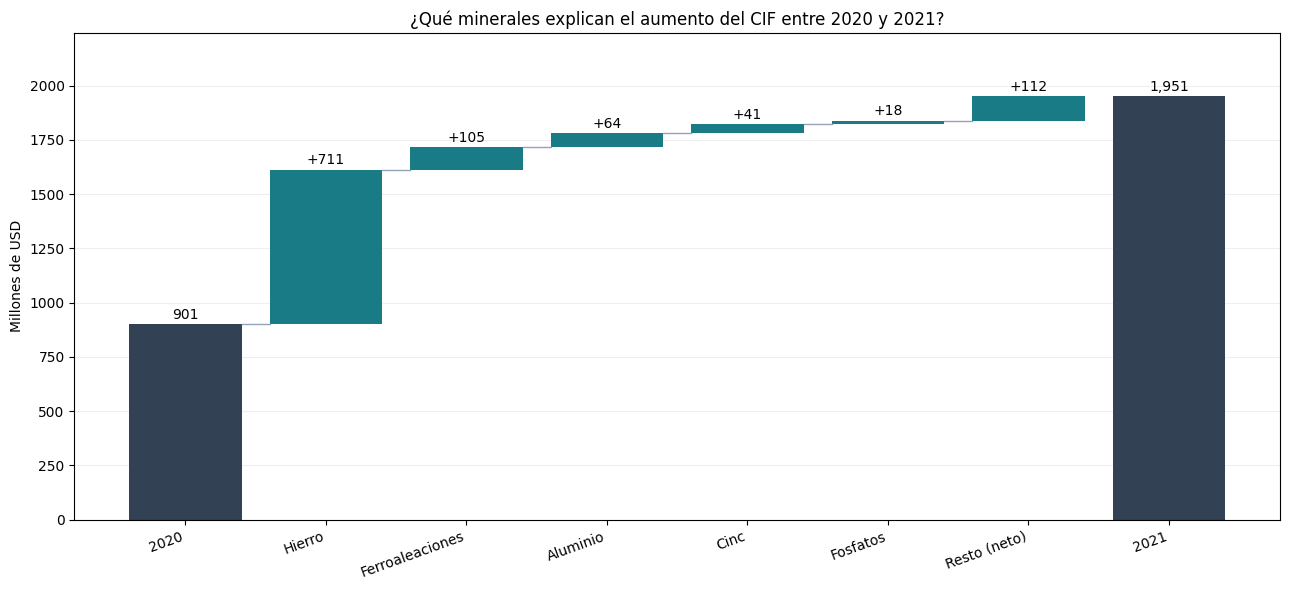

In [11]:
# Conservamos los cinco mayores aportes positivos; el resto se suma con su signo.
aportes = cambio_2021["CAMBIO_MILLONES"]
aportes_principales = aportes.head(5)
aportes_grafico = pd.concat([
    aportes_principales,
    pd.Series({"Resto (neto)": aportes.iloc[5:].sum()})
])
inicio = cif_anual.set_index("ANYO").loc[2020, "CIF_MILLONES"]
fin = cif_anual.set_index("ANYO").loc[2021, "CIF_MILLONES"]
assert np.isclose(inicio + aportes_grafico.sum(), fin), "Revisar la suma de aportes"
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(0, inicio, color="#334155")
ax.text(0, inicio + 25, f"{inicio:,.0f}", ha="center")
acumulado = inicio
for posicion, (mineral, aporte) in enumerate(aportes_grafico.items(), start=1):
    siguiente = acumulado + aporte
    ax.plot([posicion-1+0.4, posicion-0.4], [acumulado, acumulado],
            color="#94a3b8", linewidth=1)
    ax.bar(posicion, abs(aporte), bottom=min(acumulado, siguiente),
           color="#197b86" if aporte >= 0 else "#c65b46")
    ax.text(posicion, max(acumulado, siguiente) + 25,
            f"{aporte:+,.0f}", ha="center", fontsize=10)
    acumulado = siguiente
ultima = len(aportes_grafico) + 1
ax.bar(ultima, fin, color="#334155")
ax.text(ultima, fin + 25, f"{fin:,.0f}", ha="center")
ax.set_xticks(range(ultima + 1))
ax.set_xticklabels(["2020", *aportes_grafico.index, "2021"], rotation=20, ha="right")
ax.set(title="¿Qué minerales explican el aumento del CIF entre 2020 y 2021?",
       ylabel="Millones de USD")
ax.set_ylim(0, max(inicio, fin, inicio + aportes_grafico.cumsum().max()) * 1.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [12]:
# Filtramos Hierro para 2020 y 2021
hierro_pais_2021 = (
    data[
        (data["GRUPO"] == "Hierro") &
        (data["ANYO"].isin([2020, 2021]))
    ]
    .groupby(["ORIGEN", "ANYO"])["CIF"]
    .sum()
    .unstack(fill_value=0)
)

# Convertimos 2020 y 2021 a millones de USD
hierro_pais_2021[2020] = hierro_pais_2021[2020] / 1_000_000
hierro_pais_2021[2021] = hierro_pais_2021[2021] / 1_000_000

# Calculamos el cambio en millones
hierro_pais_2021["CAMBIO_MILLONES"] = (
    hierro_pais_2021[2021] - hierro_pais_2021[2020]
)

# Ordenamos de mayor a menor aumento
hierro_pais_2021 = hierro_pais_2021.sort_values(
    "CAMBIO_MILLONES",
    ascending=False
)

# Mostramos solo las columnas necesarias y redondeamos
display(
    hierro_pais_2021[
        [2020, 2021, "CAMBIO_MILLONES"]
    ].head(10).round(2)
)

ANYO,2020,2021,CAMBIO_MILLONES
ORIGEN,,,
Brasil,"264,97","897,48","632,51"
Canada,"53,93","126,43","72,50"
Rusia,"0,00","12,50","12,50"
Sudafrica,"12,34","12,98","0,64"
China,"0,03","0,12","0,09"
Italia,"0,06","0,10","0,04"
Ucrania,"0,00","0,00","0,00"
India,"0,00","0,00","0,00"
Oman,"0,00","0,00","0,00"


**Lectura:** el hierro aporta aproximadamente USD 711,5 millones al aumento de 2021. En su desglose por origen, Brasil aporta cerca de USD 632,5 millones del incremento del hierro.

## 6. Participación de los minerales

¿Cómo se reparte el CIF histórico entre los principales minerales? Mostramos los ocho grupos de mayor valor acumulado y reunimos los restantes en «Otros» para conservar el total como denominador.

In [13]:
# Tomamos los 8 minerales principales
peso_minerales = ranking_minerales.head(8)[["GRUPO", "CIF"]].copy()

# Sumamos todos los minerales restantes
otros_cif = ranking_minerales.iloc[8:]["CIF"].sum()

# Agregamos "Otros"
otros = pd.DataFrame({
    "GRUPO": ["Otros"],
    "CIF": [otros_cif]
})

peso_minerales = pd.concat(
    [peso_minerales, otros],
    ignore_index=True
)

# Calculamos participación porcentual
peso_minerales["PARTICIPACION"] = (
    peso_minerales["CIF"] /
    peso_minerales["CIF"].sum() * 100
)

display(peso_minerales.round(2))

,GRUPO,CIF,PARTICIPACION
0,Hierro,"15.083.245.160,96","40,00"
1,Aluminio,"6.729.701.828,74","17,85"
2,Ferroaleaciones,"3.045.723.819,90","8,08"
3,Cobre,"1.669.423.602,23","4,43"
4,Cinc,"1.634.876.672,87","4,34"
5,Potasio,"898.504.192,35","2,38"
6,Bauxita,"669.008.593,11","1,77"
7,Fosfatos,"648.898.409,62","1,72"
8,Otros,"7.324.230.806,20","19,43"


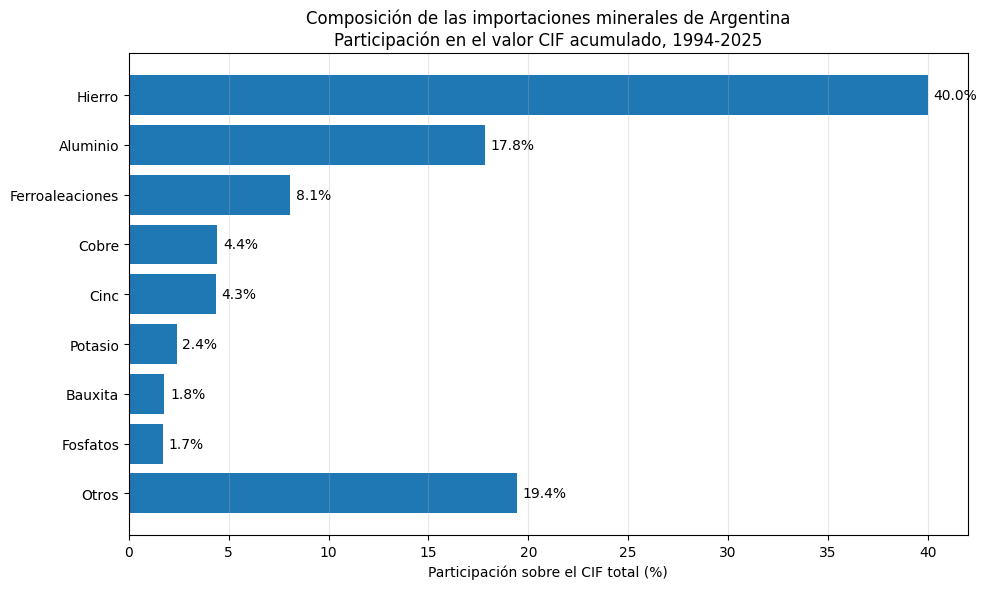

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    peso_minerales["GRUPO"],
    peso_minerales["PARTICIPACION"]
)

# Ponemos el mineral de mayor peso arriba
ax.invert_yaxis()

# Etiquetas con porcentaje
ax.bar_label(
    barras,
    fmt="%.1f%%",
    padding=4
)

ax.set_title(
    "Composición de las importaciones minerales de Argentina\n"
    "Participación en el valor CIF acumulado, 1994-2025"
)

ax.set_xlabel("Participación sobre el CIF total (%)")
ax.set_ylabel("")

ax.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

**Lectura:** los ocho grupos seleccionados reúnen aproximadamente el 80,6 % del CIF histórico. «Otros» completa el 19,4 % restante y evita confundir el subtotal de los principales minerales con el total.

## 7. Evolución por mineral

¿Los principales minerales siguen trayectorias similares? Comparamos su evolución anual, manteniendo una selección fija de los ocho grupos con mayor CIF acumulado en 1994–2025.

In [15]:
# CIF anual por mineral para los 8 minerales principales
evolucion_minerales = (
    historico[
        historico["GRUPO"].isin(top_minerales)
    ]
    .groupby(["ANYO", "GRUPO"])["CIF"]
    .sum()
    .reset_index()
)

# Pasamos a millones de USD
evolucion_minerales["CIF_MILLONES"] = (
    evolucion_minerales["CIF"] / 1_000_000
)

display(evolucion_minerales.head(20))

,ANYO,GRUPO,CIF,CIF_MILLONES
0,1994,Aluminio,"8.395.439,00","8,40"
1,1994,Cinc,"4.542.206,00","4,54"
2,1994,Cobre,"91.483.462,00","91,48"
3,1994,Ferroaleaciones,"5.737.092,00","5,74"
4,1994,Fosfatos,"31.288,00","0,03"
5,1994,Hierro,"122.668.583,00","122,67"
6,1994,Potasio,"2.094.158,00","2,09"
7,1995,Aluminio,"86.232.234,00","86,23"
8,1995,Bauxita,"3.691.562,00","3,69"
9,1995,Cinc,"11.810.494,00","11,81"


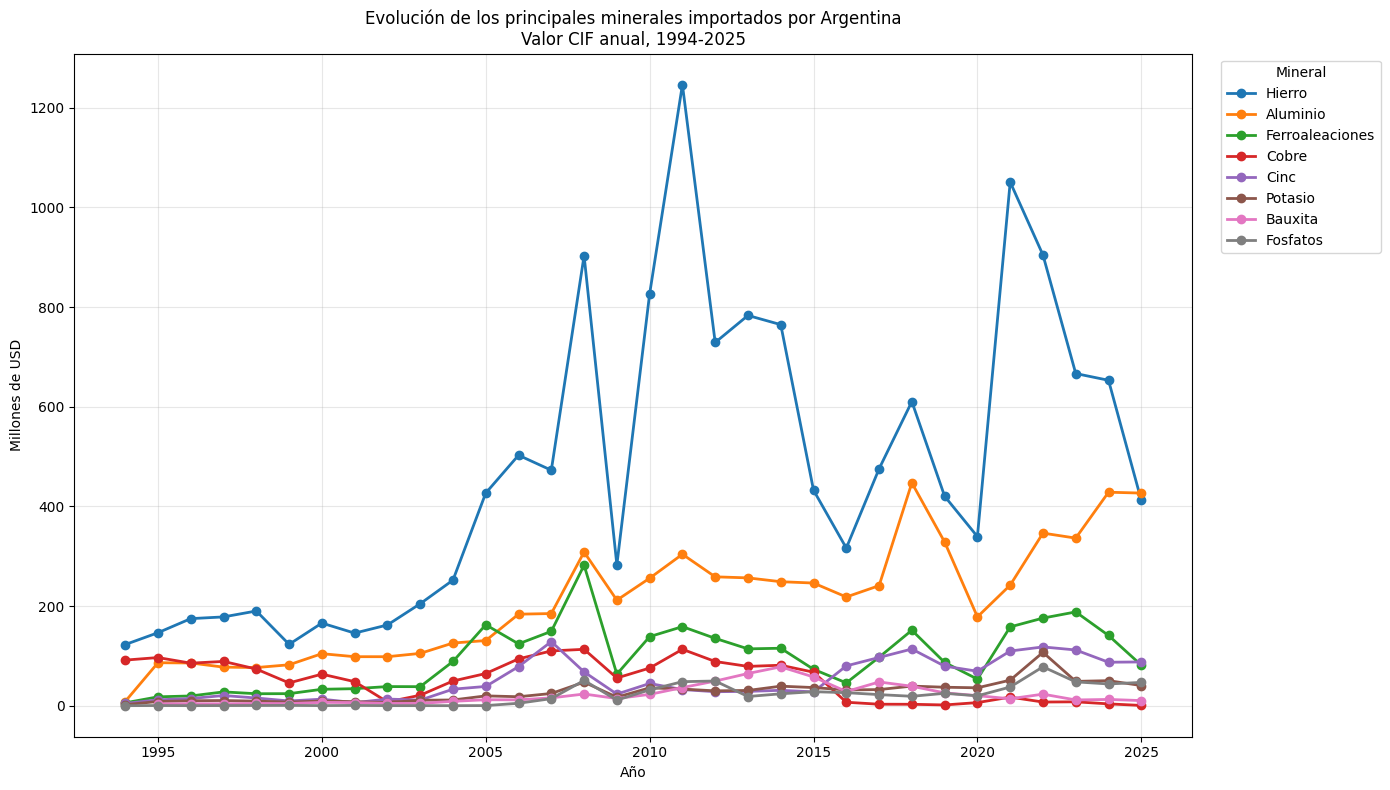

In [16]:
fig, ax = plt.subplots(figsize=(14, 8))

for mineral in top_minerales:
    datos_mineral = evolucion_minerales[
        evolucion_minerales["GRUPO"] == mineral
    ]

    ax.plot(
        datos_mineral["ANYO"],
        datos_mineral["CIF_MILLONES"],
        marker="o",
        linewidth=2,
        label=mineral
    )

ax.set_title(
    "Evolución de los principales minerales importados por Argentina\n"
    "Valor CIF anual, 1994-2025"
)

ax.set_xlabel("Año")
ax.set_ylabel("Millones de USD")

ax.legend(
    title="Mineral",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Convertimos la tabla para tener:
# filas = años
# columnas = minerales
# valores = CIF en millones de USD

barras_minerales = (
    evolucion_minerales
    .pivot(
        index="ANYO",
        columns="GRUPO",
        values="CIF_MILLONES"
    )
    .fillna(0)
)

display(barras_minerales.head())

GRUPO,Aluminio,Bauxita,Cinc,Cobre,Ferroaleaciones,Fosfatos,Hierro,Potasio
ANYO,,,,,,,,
1994,"8,40","0,00","4,54","91,48","5,74","0,03","122,67","2,09"
1995,"86,23","3,69","11,81","96,60","17,78","0,31","146,45","8,38"
1996,"85,71","3,97","14,34","85,33","19,52","0,08","174,72","9,91"
1997,"77,38","3,83","20,43","88,83","27,69","0,23","178,16","10,39"
1998,"76,54","4,49","15,39","73,51","24,01","0,41","190,05","9,15"


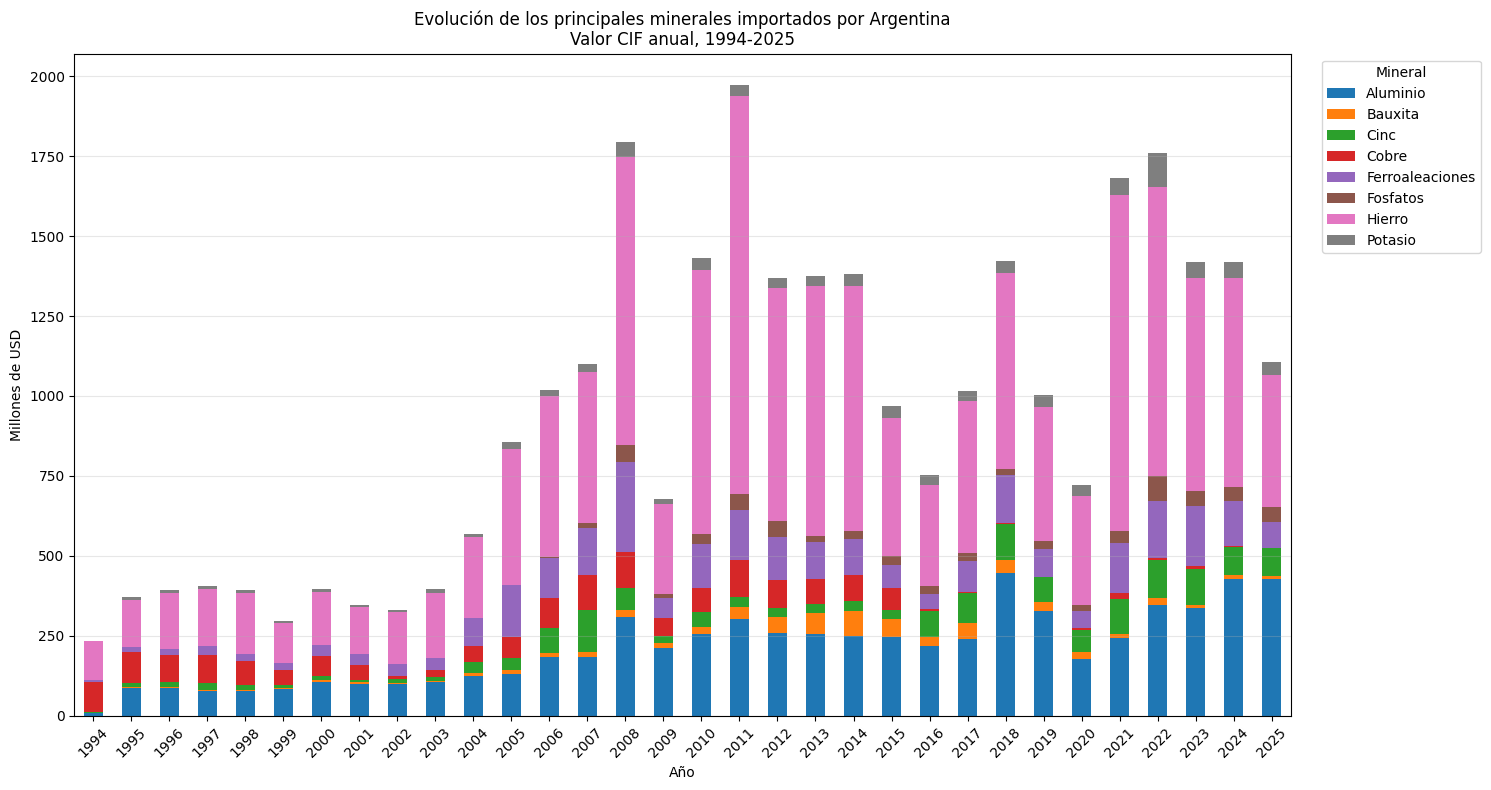

In [18]:
fig, ax = plt.subplots(figsize=(15, 8))

barras_minerales.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title(
    "Evolución de los principales minerales importados por Argentina\n"
    "Valor CIF anual, 1994-2025"
)

ax.set_xlabel("Año")
ax.set_ylabel("Millones de USD")

ax.legend(
    title="Mineral",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Alcance del gráfico:** las barras apiladas muestran solo los ocho minerales seleccionados; no equivalen al total importado. El gráfico de líneas facilita comparar trayectorias y las barras, la composición de ese subtotal. Para una presentación breve puede dejarse solo uno.

## 8. Caso de estudio: uranio, origen y procedencia

¿En qué medida coincide el país de origen con el de procedencia en las importaciones registradas de uranio? Este caso profundiza el análisis general al cruzar dos campos de la base y comparar tanto los montos como sus proporciones.

Primero observamos el valor CIF anual de 1994–2025. Después analizamos el porcentaje con países distintos y las tablas de respaldo. Esta secuencia permite interpretar los porcentajes teniendo presente la magnitud monetaria.

### 8.1. Magnitud y composición anual

Las barras apiladas muestran el CIF con origen y procedencia iguales o distintos, en millones de USD. Normalizamos mayúsculas y espacios de los nombres y comparamos únicamente registros con ambos países informados. En esta base, todos los registros de uranio del período cumplen esa condición.

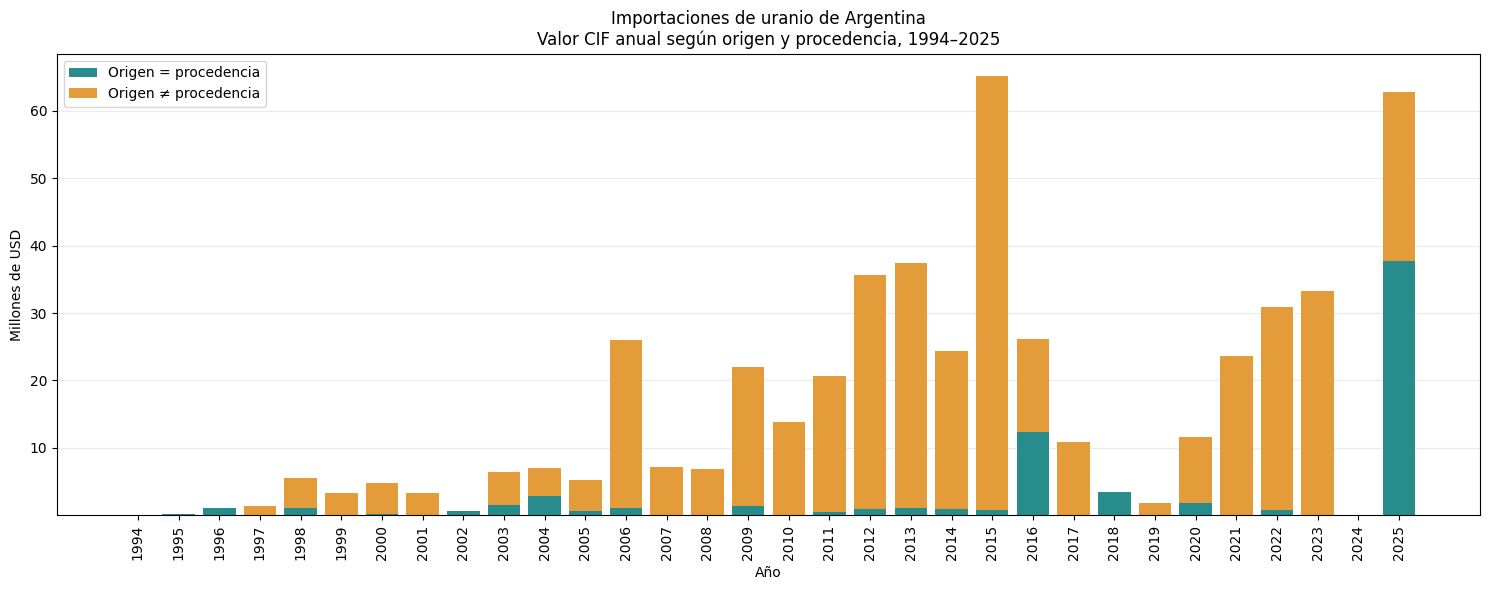

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Uranio: mismo período histórico del notebook.
u_barras = historico.loc[
    historico["GRUPO"] == "Uranio"
].copy()

# Normalizamos los países antes de compararlos.
origen = u_barras["ORIGEN"].astype("string").str.strip().str.casefold()
procedencia = u_barras["PROCEDENC"].astype("string").str.strip().str.casefold()

# Solo comparamos cuando ambos países están informados.
validos = (
    origen.notna()
    & procedencia.notna()
    & ~origen.isin(["", "sin dato"])
    & ~procedencia.isin(["", "sin dato"])
)

excluidos = (~validos).sum()
u_barras = u_barras.loc[validos].copy()

u_barras["Relación"] = "Origen = procedencia"
u_barras.loc[
    origen.loc[validos] != procedencia.loc[validos],
    "Relación"
] = "Origen ≠ procedencia"

# Sumamos por año y relación; convertimos a millones de USD.
uranio_apilado = (
    u_barras.groupby(["ANYO", "Relación"])["CIF"]
    .sum(min_count=1)
    .unstack(fill_value=0)
    .reindex(
        columns=["Origen = procedencia", "Origen ≠ procedencia"],
        fill_value=0
    )
    .reindex(range(1994, 2026))
    / 1_000_000
)

fig, ax = plt.subplots(figsize=(15, 6))

ax.bar(
    uranio_apilado.index,
    uranio_apilado["Origen = procedencia"],
    label="Origen = procedencia",
    color="#298c8c"
)

ax.bar(
    uranio_apilado.index,
    uranio_apilado["Origen ≠ procedencia"],
    bottom=uranio_apilado["Origen = procedencia"],
    label="Origen ≠ procedencia",
    color="#e49b39"
)

ax.set(
    title="Importaciones de uranio de Argentina\n"
          "Valor CIF anual según origen y procedencia, 1994–2025",
    xlabel="Año",
    ylabel="Millones de USD"
)

ax.set_xticks(uranio_apilado.index)
ax.tick_params(axis="x", rotation=90)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", "."))
)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

if excluidos:
    print(f"Se excluyeron {excluidos} registros sin ambos países informados.")

**Lectura:** en 2025, el CIF de uranio suma USD 62,81 millones: USD 37,76 millones con países coincidentes y USD 25,05 millones con países distintos. El valor de 2024 —USD 55,55 en una sola fila— es prácticamente invisible a esta escala; no equivale a cero y debe contrastarse con la fuente.

### 8.2. Participación con origen y procedencia distintos

**Porcentaje = CIF con países distintos / CIF con ambos países informados × 100.**

El indicador mide participación monetaria, no volumen físico ni proporción de operaciones. Se conserva la tabla anual para verificar el denominador. Un año sin filas se deja sin dato, sin asumir importaciones nulas.

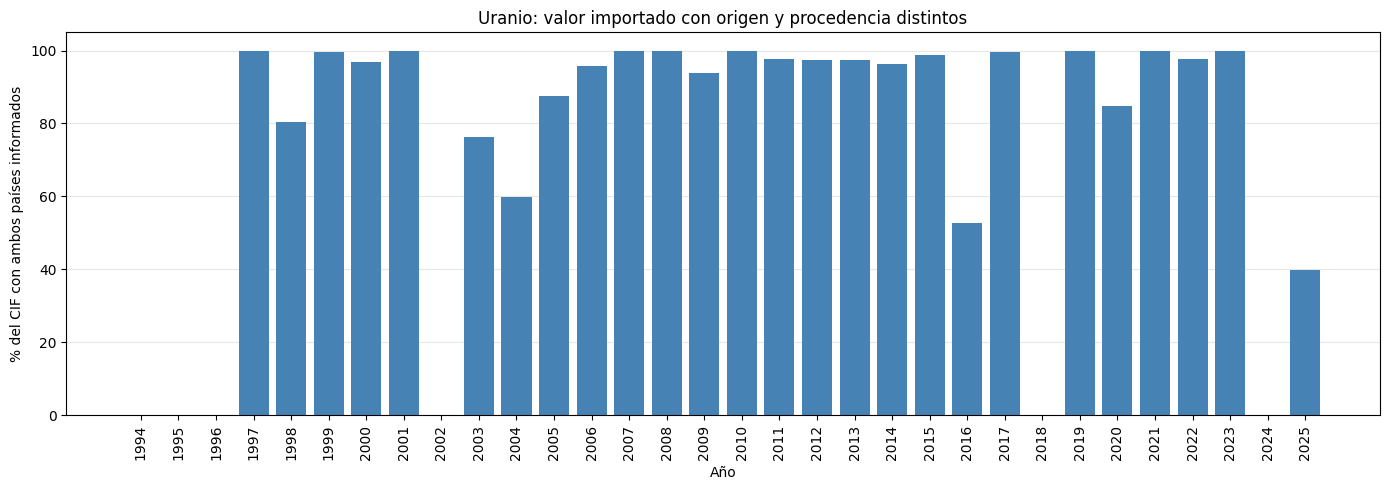

,CIF total (USD),Cantidad de registros,CIF con ambos países informados (USD),Origen ≠ procedencia (% del CIF comparable)
Año,,,,
1994,"3.278,00",1,"3.278,00","0,0%"
1995,"142.088,00",16,"142.088,00","0,0%"
1996,"1.021.855,00",9,"1.021.855,00","0,0%"
1997,"1.380.593,00",8,"1.380.593,00","99,8%"
1998,"5.495.971,90",14,"5.495.971,90","80,4%"
1999,"3.342.575,18",10,"3.342.575,18","99,6%"
2000,"4.836.589,06",12,"4.836.589,06","96,8%"
2001,"3.318.984,84",6,"3.318.984,84","99,9%"
2002,"673.545,66",3,"673.545,66","0,0%"


In [20]:
# Selección temporal: uranio del histórico 1994–2025
u_temp = historico.loc[historico["GRUPO"] == "Uranio"].copy()

# Normalizamos los nombres para comparar
origen_temp = u_temp["ORIGEN"].astype("string").str.strip().str.casefold()
procedencia_temp = u_temp["PROCEDENC"].astype("string").str.strip().str.casefold()

# Comparamos solo registros con ambos países informados
validos_temp = (
    origen_temp.notna()
    & procedencia_temp.notna()
    & ~origen_temp.isin(["", "sin dato"])
    & ~procedencia_temp.isin(["", "sin dato"])
)

u_temp = u_temp.loc[validos_temp].copy()

u_temp["CIF_DISTINTO"] = u_temp["CIF"].where(
    origen_temp.loc[validos_temp] != procedencia_temp.loc[validos_temp],
    0
)

# Calculamos el porcentaje sobre el CIF comparable de cada año
resumen_temp = (
    u_temp.groupby("ANYO")[["CIF", "CIF_DISTINTO"]]
    .sum()
    .reindex(range(1994, 2026))
)

porcentaje_temp = (
    resumen_temp["CIF_DISTINTO"]
    / resumen_temp["CIF"].where(resumen_temp["CIF"] > 0)
    * 100
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(porcentaje_temp.index, porcentaje_temp, color="steelblue")

ax.set(
    title="Uranio: valor importado con origen y procedencia distintos",
    xlabel="Año",
    ylabel="% del CIF con ambos países informados",
    ylim=(0, 105)
)

ax.set_xticks(range(1994, 2026))
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)


plt.tight_layout()
plt.show()

# Totales anuales: incluimos todos los registros de uranio,
# aunque no tengan origen o procedencia informados.
totales_uranio = (
    historico.loc[historico["GRUPO"] == "Uranio"]
    .groupby("ANYO")
    .agg(
        CIF_TOTAL=("CIF", lambda serie: serie.sum(min_count=1)),
        REGISTROS=("CIF", "size")
    )
    .reindex(range(1994, 2026))
)

# Unimos los totales con la base utilizada para calcular el porcentaje.
tabla_uranio = totales_uranio.copy()

tabla_uranio["CIF_COMPARABLE"] = resumen_temp["CIF"]
tabla_uranio["PORCENTAJE_DISTINTO"] = porcentaje_temp

# Un año sin filas tiene cero registros.
# Su CIF se deja sin dato: no asumimos que hubo cero importaciones.
tabla_uranio["REGISTROS"] = (
    tabla_uranio["REGISTROS"].fillna(0).astype(int)
)

tabla_uranio.index.name = "Año"

tabla_uranio = tabla_uranio.rename(columns={
    "CIF_TOTAL": "CIF total (USD)",
    "REGISTROS": "Cantidad de registros",
    "CIF_COMPARABLE": "CIF con ambos países informados (USD)",
    "PORCENTAJE_DISTINTO": "Origen ≠ procedencia (% del CIF comparable)"
})

display(
    tabla_uranio.style.format(
        {
            "CIF total (USD)": "{:,.2f}",
            "Cantidad de registros": "{:,.0f}",
            "CIF con ambos países informados (USD)": "{:,.2f}",
            "Origen ≠ procedencia (% del CIF comparable)": "{:,.1f}%"
        },
        thousands=".",
        decimal=",",
        na_rep="Sin dato"
    )
)

**Lectura:** la participación con países distintos fue del 100,0 % en 2021, 97,7 % en 2022 y 99,99 % en 2023; en 2025 fue del 39,9 %. El 0 % de 2024 se calcula sobre apenas USD 55,55. Por eso, el porcentaje aislado no describe la importancia monetaria de cada año.

### 8.3. Tablas de respaldo

Las siguientes tablas permiten inspeccionar montos, países y combinaciones declaradas. Los rankings corresponden al período acumulado. Las filas son registros de la base, no necesariamente operaciones individuales; los meses sin registros de uranio no prueban falta de cobertura general.

La variación porcentual de 2025 tiene como base el importe excepcionalmente bajo de 2024 y no se utiliza como hallazgo principal. Las combinaciones de países no reconstruyen por sí solas una ruta física ni prueban intermediación.

In [21]:
# URANIO: análisis desde distintas perspectivas
import pandas as pd
from IPython.display import display

DESDE, HASTA = 1994, 2025
TOP = 10

# Trabajamos sobre una copia, sin modificar data.
base_u = data.loc[data["ANYO"].between(DESDE, HASTA)].copy()
uranio = base_u.loc[
    base_u["GRUPO"].astype("string").str.strip().str.casefold().eq("uranio")
].copy()

if uranio.empty:
    raise ValueError("No hay registros de uranio en el período elegido.")

# Normalizamos países; conservamos los faltantes como categoría explícita.
for columna in ["ORIGEN", "PROCEDENC"]:
    uranio[columna] = (
        uranio[columna]
        .astype("string")
        .str.strip()
        .str.casefold()
        .replace({"": pd.NA, "sin dato": pd.NA})
        .fillna("Sin dato")
    )

# Formato local: miles con punto, sin decimales innecesarios.
def mostrar_u(titulo, tabla):
    print(f"\n{titulo}")
    formatos = {
        columna: ("{:,.2f}" if "%" in str(columna) else "{:,.0f}")
        for columna in tabla.select_dtypes(include="number").columns
    }
    display(
        tabla.style.format(
            formatos, thousands=".", decimal=",", na_rep="Sin dato"
        )
    )

total_u = uranio["CIF"].sum(min_count=1)

print(f"URANIO | {DESDE}–{HASTA}")
print(f"Registros: {len(uranio)}")
print(f"CIF acumulado: USD {total_u:,.0f}".replace(",", "."))
print("Los registros son filas del dataset; no necesariamente operaciones.")

# 1. Evolución anual y peso dentro del total de minerales.
anual_u = (
    uranio.groupby("ANYO")
    .agg(
        CIF_USD=("CIF", lambda s: s.sum(min_count=1)),
        Registros=("CIF", "size"),
        Meses_con_registros=("MES", "nunique")
    )
    .reindex(range(DESDE, HASTA + 1))
)

# La ausencia de filas no se interpreta como CIF cero.
anual_u[["Registros", "Meses_con_registros"]] = (
    anual_u[["Registros", "Meses_con_registros"]].fillna(0).astype(int)
)

anterior_u = anual_u["CIF_USD"].shift(1)
anual_u["Cambio_USD"] = anual_u["CIF_USD"] - anterior_u
anual_u["Variación_%"] = (
    anual_u["Cambio_USD"] / anterior_u.where(anterior_u > 0) * 100
)

total_minerales_u = base_u.groupby("ANYO")["CIF"].sum(min_count=1)
anual_u["Peso_en_minerales_%"] = (
    anual_u["CIF_USD"]
    / total_minerales_u.where(total_minerales_u > 0) * 100
)

mostrar_u("1. EVOLUCIÓN ANUAL", anual_u)

# 2 y 3. Rankings por origen y por procedencia.
def ranking_u(columna):
    tabla = (
        uranio.groupby(columna)
        .agg(
            CIF_USD=("CIF", lambda s: s.sum(min_count=1)),
            Registros=("CIF", "size"),
            Años_con_registros=("ANYO", "nunique")
        )
        .sort_values("CIF_USD", ascending=False)
    )
    tabla["Participación_%"] = tabla["CIF_USD"] / total_u * 100
    tabla["Acumulado_%"] = tabla["Participación_%"].cumsum()
    return tabla

origenes_u = ranking_u("ORIGEN")
procedencias_u = ranking_u("PROCEDENC")

mostrar_u("2. PAÍSES DE ORIGEN", origenes_u.head(TOP))
mostrar_u("3. PAÍSES DE PROCEDENCIA", procedencias_u.head(TOP))

# 4. Combinaciones de origen y procedencia declaradas.
pares_u = (
    uranio.groupby(["ORIGEN", "PROCEDENC"])
    .agg(
        CIF_USD=("CIF", lambda s: s.sum(min_count=1)),
        Registros=("CIF", "size")
    )
    .sort_values("CIF_USD", ascending=False)
)
pares_u["Participación_%"] = pares_u["CIF_USD"] / total_u * 100

mostrar_u("4. PRINCIPALES COMBINACIONES ORIGEN–PROCEDENCIA", pares_u.head(TOP))

# 5. Coincidencia: distinguimos peso en dinero y cantidad de filas.
comparables_u = (
    uranio["ORIGEN"].ne("Sin dato")
    & uranio["PROCEDENC"].ne("Sin dato")
)

uranio["Relación"] = "Sin información suficiente"
uranio.loc[comparables_u, "Relación"] = "Iguales"
uranio.loc[
    comparables_u & uranio["ORIGEN"].ne(uranio["PROCEDENC"]),
    "Relación"
] = "Distintos"

relacion_u = (
    uranio.groupby("Relación")
    .agg(
        CIF_USD=("CIF", lambda s: s.sum(min_count=1)),
        Registros=("CIF", "size")
    )
)
relacion_u["%_del_CIF_total"] = relacion_u["CIF_USD"] / total_u * 100
relacion_u["%_de_registros"] = relacion_u["Registros"] / len(uranio) * 100

mostrar_u("5. ¿COINCIDEN ORIGEN Y PROCEDENCIA?", relacion_u)

# 6. Filas de mayor valor: permite inspeccionar qué concentra el total.
mayores_u = (
    uranio.nlargest(TOP, "CIF")
    [["ANYO", "MES", "ORIGEN", "PROCEDENC", "CIF"]]
    .rename(columns={"CIF": "CIF_USD"})
    .copy()
)
mayores_u["Participación_%"] = mayores_u["CIF_USD"] / total_u * 100

mostrar_u("6. REGISTROS CON MAYOR CIF", mayores_u.reset_index(drop=True))

URANIO | 1994–2025
Registros: 212
CIF acumulado: USD 502.371.717
Los registros son filas del dataset; no necesariamente operaciones.

1. EVOLUCIÓN ANUAL

2. PAÍSES DE ORIGEN

3. PAÍSES DE PROCEDENCIA

4. PRINCIPALES COMBINACIONES ORIGEN–PROCEDENCIA

5. ¿COINCIDEN ORIGEN Y PROCEDENCIA?

6. REGISTROS CON MAYOR CIF


,CIF_USD,Registros,Meses_con_registros,Cambio_USD,Variación_%,Peso_en_minerales_%
ANYO,,,,,,
1994,3.278,1,1,Sin dato,Sin dato,"0,00"
1995,142.088,16,10,138.810,"4.234,59","0,03"
1996,1.021.855,9,7,879.767,"619,17","0,18"
1997,1.380.593,8,6,358.738,"35,11","0,23"
1998,5.495.972,14,9,4.115.379,"298,09","0,93"
1999,3.342.575,10,6,-2.153.397,"-39,18","0,72"
2000,4.836.589,12,9,1.494.014,"44,70","0,87"
2001,3.318.985,6,5,-1.517.604,"-31,38","0,69"
2002,673.546,3,3,-2.645.439,"-79,71","0,17"


,CIF_USD,Registros,Años_con_registros,Participación_%,Acumulado_%
ORIGEN,,,,,
canada,207.935.905,60,23,"41,39","41,39"
kazajstan,132.518.516,9,7,"26,38","67,77"
estados unidos,48.110.934,47,26,"9,58","77,35"
suecia,30.884.060,13,11,"6,15","83,49"
namibia,25.053.047,4,1,"4,99","88,48"
republica checa,21.684.232,5,4,"4,32","92,80"
brasil,12.174.818,9,8,"2,42","95,22"
rusia,8.851.432,5,5,"1,76","96,98"
uzbekistan,7.965.979,4,2,"1,59","98,57"


,CIF_USD,Registros,Años_con_registros,Participación_%,Acumulado_%
PROCEDENC,,,,,
estados unidos,283.747.335,73,27,"56,48","56,48"
alemania,182.858.281,59,20,"36,40","92,88"
suecia,14.661.317,6,5,"2,92","95,80"
brasil,13.351.028,23,11,"2,66","98,46"
canada,3.329.746,28,14,"0,66","99,12"
belgica,3.286.478,5,4,"0,65","99,77"
rusia,921.559,1,1,"0,18","99,96"
francia,97.192,2,2,"0,02","99,98"
españa,70.245,2,2,"0,01","99,99"


,CIF_USD,Registros,%_del_CIF_total,%_de_registros
Relación,,,,
Distintos,431.600.889,85,"85,91","40,09"
Iguales,70.770.828,127,"14,09","59,91"


,ANYO,MES,ORIGEN,PROCEDENC,CIF_USD,Participación_%
0,2.023,12,kazajstan,estados unidos,33.204.944,"6,61"
1,2.022,4,kazajstan,estados unidos,27.004.777,"5,38"
2,2.025,8,estados unidos,estados unidos,23.797.172,"4,74"
3,2.025,12,namibia,estados unidos,21.793.534,"4,34"
4,2.015,9,canada,estados unidos,20.175.780,"4,02"
5,2.015,12,canada,estados unidos,20.011.798,"3,98"
6,2.021,6,kazajstan,estados unidos,18.548.575,"3,69"
7,2.013,5,canada,alemania,17.234.537,"3,43"
8,2.013,12,canada,alemania,16.295.063,"3,24"
9,2.012,12,canada,alemania,16.007.160,"3,19"


## Conclusiones y pendientes

Resultados del análisis de 1994–2025:

- **Concentración por mineral:** hierro representa aproximadamente el **40,0 %** del CIF histórico y aluminio el **17,8 %**; juntos suman el **57,9 %**.
- **Concentración por origen:** Brasil reúne aproximadamente el **58,8 %** del valor acumulado. Esto describe las importaciones observadas, no la dependencia sobre el consumo nacional.
- **Evolución nominal:** el máximo anual corresponde a **2011**, con unos **USD 2.297,5 millones**. Los cambios de CIF no permiten separar precios y cantidades.
- **Salto de 2021:** el CIF aumentó aproximadamente **116,5 %** frente a 2020. El hierro aportó unos **USD 711,5 millones** del incremento; se trata de una descomposición contable, no de una explicación causal.
- **Caso del uranio:** en 2025 se registraron **USD 62,81 millones**, de los cuales **39,9 %** correspondió a origen y procedencia distintos. Interpretar el porcentaje junto con el monto evita equiparar años de escalas muy diferentes.
- **Dato por contrastar:** en 2024, el uranio presenta un único registro por **USD 55,55**. Su importe excepcionalmente bajo requiere contrastar la fuente antes de atribuirle una explicación económica. La base general sí contiene registros en los doce meses de ese año.

**Alcance y límites:** los importes son CIF nominales en USD; las filas no equivalen necesariamente a operaciones individuales. Las diferencias entre origen y procedencia no demuestran por sí solas intermediación, rutas físicas ni sus causas. La ausencia de registros de un mineral en un mes tampoco acredita importaciones nulas.

**Antes de publicar:** completar el enlace de descarga, la fecha de consulta y las definiciones de los campos de la fuente; contrastar el dato de uranio de 2024. El CSV debe acompañar al notebook con el nombre indicado en la carga. Para incorporar 2026, comparar los mismos meses de 2025 y 2026.